# Lab 7A: Optical Satellite Imagery — Spectral Bands & False Color

> **Colab note:** This notebook is designed to run on **Google Colab**. [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/amtseismo/EPS166/blob/main/notebooks/07a_optical_false_color.ipynb)

## Introduction

Optical satellites record reflected sunlight across multiple wavelength bands simultaneously. By choosing which bands to assign to the red, green, and blue display channels, we can reveal surface properties — vegetation, mineralogy, moisture — that are invisible to the human eye.

In this lab you will explore multispectral Sentinel-2 imagery over Crater Lake, Oregon

## Learning objectives

By the end of this lab you will be able to:

- Load and display individual spectral bands from a multispectral satellite image
- Construct true-color, color-infrared (CIR), and geology composites
- Calculate and interpret NDVI

## Notebook outline

1. [Setup](#setup)
2. [Part I: Crater Lake — spectral exploration](#part-i-crater-lake--spectral-exploration)


## Setup

Install and import required packages.


In [1]:
%pip install -q rasterio pyproj pystac-client planetary-computer

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from scipy.ndimage import map_coordinates
import urllib.request, os, warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({"figure.dpi": 130, "axes.grid": False})
print("Setup complete.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 2.7 MB/s eta 0:00:00
Setup complete.


---

## Part I: Crater Lake — spectral band exploration

Crater Lake, Oregon occupies the caldera of Mount Mazama, a volcano that collapsed ~7,700 years ago. It is one of the deepest lakes in the world (~590 m) and is surrounded by dense old-growth conifer forest. The scene contains four spectrally distinct surface types:

| Surface | Spectral character |
|---|---|
| **Deep lake water** | Some penetration in blue; absorbs strongly in green, NIR, and SWIR |
| **Dense conifer forest** | Absorbs red (chlorophyll); reflects strongly in NIR (leaf cell structure) |
| **Bare volcanic rock** | Intermediate reflectance; SWIR reveals mineralogy and alteration |
| **Snow / ice** | Bright in all visible bands; dark in SWIR (water in ice absorbs it) |

We begin with a true-color reference image so you can orient yourself in the scene, then examine individual spectral bands, and finally build false-colour composites that reveal features the eye cannot see.

### Download the Crater Lake scene

In [2]:
# Pre-clipped Sentinel-2 L2A bands over Crater Lake (10 m resolution)
# Bands: B02 (Blue), B03 (Green), B04 (Red), B08 (NIR), B11 (SWIR-1), B12 (SWIR-2)
CRATER_BASE = (
    "https://raw.githubusercontent.com/amtseismo/EPS166/"
    "main/datasets/CraterLake/"
)
CRATER_BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]

for band in CRATER_BANDS:
    fname = f"CraterLake_{band}.tif"
    if not os.path.exists(fname):
        print(f"Downloading {fname}...")
        urllib.request.urlretrieve(CRATER_BASE + fname, fname)
print("All Crater Lake bands downloaded.")


All Crater Lake bands downloaded.


### Load the bands

In [3]:
def load_band(path, upsample_shape=None):
    """Load a single-band GeoTIFF. Optionally resample to upsample_shape (rows, cols)."""
    with rasterio.open(path) as src:
        if upsample_shape:
            arr = src.read(1, out_shape=upsample_shape,
                           resampling=Resampling.bilinear).astype(np.float32)
        else:
            arr = src.read(1).astype(np.float32)
        transform = src.transform
        nodata = src.nodata
    if nodata is not None:
        arr[arr == nodata] = np.nan
    return arr, transform

def pct(arr, lo=2, hi=98):
    """Percentile stretch to [0,1] for display."""
    vmin, vmax = np.nanpercentile(arr, [lo, hi])
    return np.clip((arr - vmin) / (vmax - vmin), 0, 1)

# Load 10 m bands
b02, tf = load_band("CraterLake_B02.tif")   # Blue
b03, _  = load_band("CraterLake_B03.tif")   # Green
b04, _  = load_band("CraterLake_B04.tif")   # Red
b08, _  = load_band("CraterLake_B08.tif")   # NIR

# SWIR bands are 20 m — resample to match 10 m grid
shape10 = b04.shape
b11, _  = load_band("CraterLake_B11.tif", upsample_shape=shape10)  # SWIR-1
b12, _  = load_band("CraterLake_B12.tif", upsample_shape=shape10)  # SWIR-2

print(f"Image size: {b04.shape[0]} x {b04.shape[1]} pixels  ({b04.shape[0]*10/1000:.1f} x {b04.shape[1]*10/1000:.1f} km)")

# Store scene CRS and transform for use in the crop cell below
with rasterio.open("CraterLake_B04.tif") as _src:
    scene_crs = _src.crs
    scene_transform = _src.transform

Image size: 1800 x 2222 pixels  (18.0 x 22.2 km)


In [4]:
def make_composite(r, g, b, lo=2, hi=98):
    """Stack three bands into an RGB display array."""
    return np.dstack([pct(r, lo, hi), pct(g, lo, hi), pct(b, lo, hi)])

### True color — scene orientation

Before exploring individual bands, establish a reference. The true-color composite assigns the visible bands (Red→R, Green→G, Blue→B) to produce an image close to what your eye would see from space.

As you look at the image, locate the following features — you will return to them repeatedly in the sections below:

- **The lake** — the deep blue interior
- **Dense conifer forest** — dark green slopes surrounding the caldera
- **Bare volcanic rock** — the exposed caldera rim and walls
- **Wizard Island** — a small cinder cone in the western part of the lake, erupted *inside* the caldera after the collapse (~7,700 years ago and therefore younger than the caldera walls); look for a dark speck of rock surrounded by shallow water
- **Snow / ice patches** — bright white, typically on the upper rim


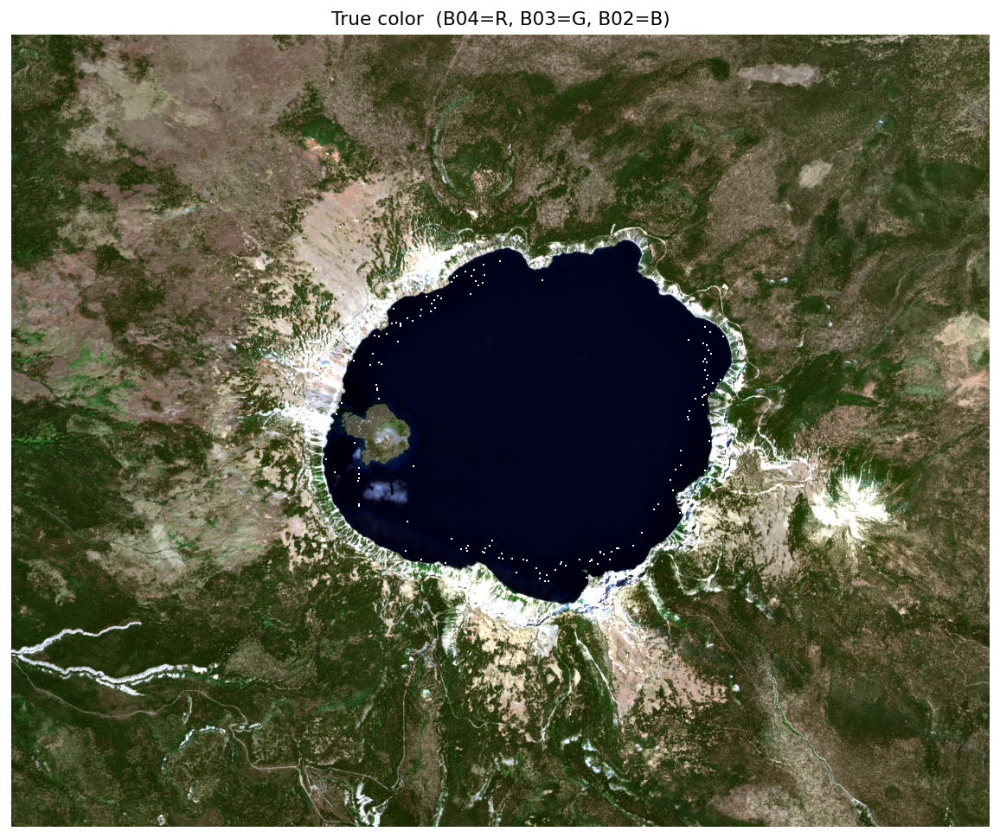

In [5]:
true_color = make_composite(b04, b03, b02)

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(true_color)
ax.set_title("True color  (B04=R, B03=G, B02=B)", fontsize=12)
ax.axis("off")
plt.tight_layout()
plt.show()

> **Questions — true color:**
> 1. **Identify four surface types.** Find one clear example of each and describe its location (e.g. "northwest rim," "centre of the lake"). What visual clue — color, brightness, or texture — made you confident in each? *(You may notice small bright speckles over the dark lake water — these are likely sensor noise, which is most visible where the true signal is very low.)*
>    - Dense conifer forest
>    - Bare volcanic rock
>    - Deep lake water
>    - Snow or ice
> 2. **What makes this a "true color" image?** Which Sentinel-2 bands are assigned to the red, green, and blue display channels? Why does this combination produce an image that looks natural to the human eye when the satellite records many more wavelengths than just three?
> 3. **Limits of true color.** Look at the caldera rim. Can you distinguish different rock types or degrees of weathering, or does the bare rock appear fairly uniform? Keep this observation in mind when you reach the geology composite later in the lab.


Answer:
1. One feature is the big lake in the crater, by color this is blue. The dense confier forest is very green in color, the more dense the trees are (like near the bottom of the crater at the mouth), the darker in green they appear. The bare volcanic rock is very brown or gray with lack of vegetation, this can be seen in the northwest. the snow and ice is very white seen on the rim and also as it is melting down into streams off the side to the bottom left.
2. This is a true color image because it is made up of bands 2,3, and 4, which are the blue, green and red bands. These are the actual colors that humans can visually see, and is what can create all other colors when mixed.
3. The bare rock appears pretty uniform, so it is difficult to distinguish the different rock types. You cannot see degrees of weathering.


### Visible bands — zoomed to Wizard Island

The deep open lake absorbs most incoming light uniformly across the visible spectrum, so a whole-scene view shows little difference between the Blue, Green, and Red bands. To see the spectral contrast that *does* exist in water, we zoom to the Wizard Island area, where shallow water near the shore, the bare volcanic rock of the island, and the deep surrounding lake are all present within a small area.

Each band is displayed in its own color map so the spectral identity of each panel is immediately visible. The color bar beneath each panel runs from **Absorbed** (little light returns to the sensor) to **Reflected** (a lot of light returns to the sensor):

- **Blue (B02):** Penetrates clear water more deeply than other visible wavelengths; also scattered by atmospheric particles and aerosols
- **Green (B03):** Captures peak vegetation reflectance in the visible — the reason leaves look green
- **Red (B04):** Absorbed by chlorophyll for photosynthesis; healthy vegetation appears dark here


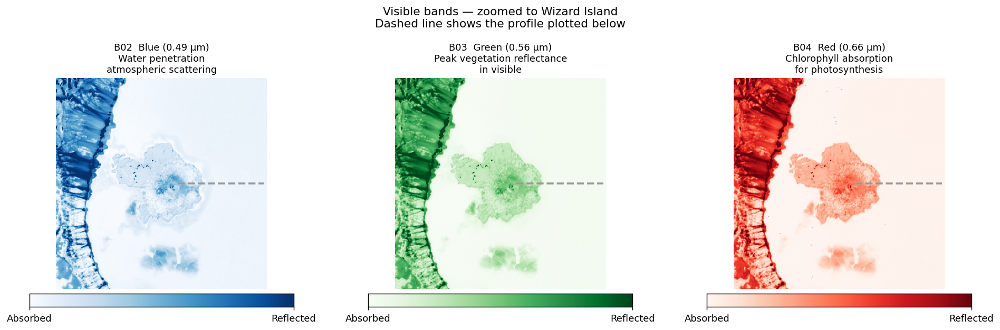

In [6]:
import pyproj
from rasterio.transform import rowcol

# Wizard Island centre coordinate (WGS84)
WIZ_LAT, WIZ_LON = 42.939390, -122.148470

transformer = pyproj.Transformer.from_crs(
    "EPSG:4326", scene_crs, always_xy=True
)
wiz_x, wiz_y = transformer.transform(WIZ_LON, WIZ_LAT)
cy, cx = rowcol(scene_transform, wiz_x, wiz_y)
cy, cx = int(cy), int(cx)

pad = int(min(b04.shape) * 0.10)
rs = slice(max(0, cy - pad), cy + pad)
cs = slice(max(0, cx - pad), cx + pad)

# Profile coordinates (reused in the profile cell below)
profile_len = 200
prof_r  = pad                          # horizontal transect through island centre
prof_c0 = pad + int(pad * 0.15)        # start: slightly east of island centre, still on rock
prof_c1 = cs.stop - cs.start - 5      # end: eastern edge of crop

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
vis_bands = [
    (b02[rs, cs], "B02  Blue (0.49 µm)",  "Blues",  "Water penetration\natmospheric scattering"),
    (b03[rs, cs], "B03  Green (0.56 µm)", "Greens", "Peak vegetation reflectance\nin visible"),
    (b04[rs, cs], "B04  Red (0.66 µm)",   "Reds",   "Chlorophyll absorption\nfor photosynthesis"),
]
for ax, (band, title, cmap, subtitle) in zip(axes, vis_bands):
    im = ax.imshow(pct(band), cmap=cmap)
    # Overlay the profile transect as a dashed line
    ax.plot([prof_c0, prof_c1], [prof_r, prof_r], color="white", lw=2.0, ls="--")
    ax.plot([prof_c0, prof_c1], [prof_r, prof_r], color="black", lw=2.0, ls="--", alpha=0.4)
    ax.set_title(f"{title}\n{subtitle}", fontsize=10)
    ax.axis("off")
    cbar = plt.colorbar(im, ax=ax, orientation="horizontal", pad=0.02, shrink=0.8)
    cbar.set_ticks([0, 1])
    cbar.set_ticklabels(["Absorbed", "Reflected"])

plt.suptitle(
    "Visible bands — zoomed to Wizard Island\n"
    "Dashed line shows the profile plotted below",
    fontsize=12,
)
plt.tight_layout()
plt.show()


> **Questions — visible bands:**
> 1. Compare the three panels side by side, focusing on the area where Wizard Island meets the water. Which band looks noticeably different from the other two at the island's edge? Describe what you see.
> 2. Using the color bars as a guide — "Absorbed" means little light returns to the sensor, "Reflected" means a lot — look at the shallow water immediately around Wizard Island. Which band shows the highest reflectance there? Which shows the lowest?

Answer:
1. The blue band shows more detail off the "coast" of the island. This is because it is likely because blue can penetrate through water more than the other bands color.
2. Blue shows the highest reflectance near the shallow water around the island since there is visible change in color around this area. I think the green and red are equally low around the island since there are no changes in color near the coast.


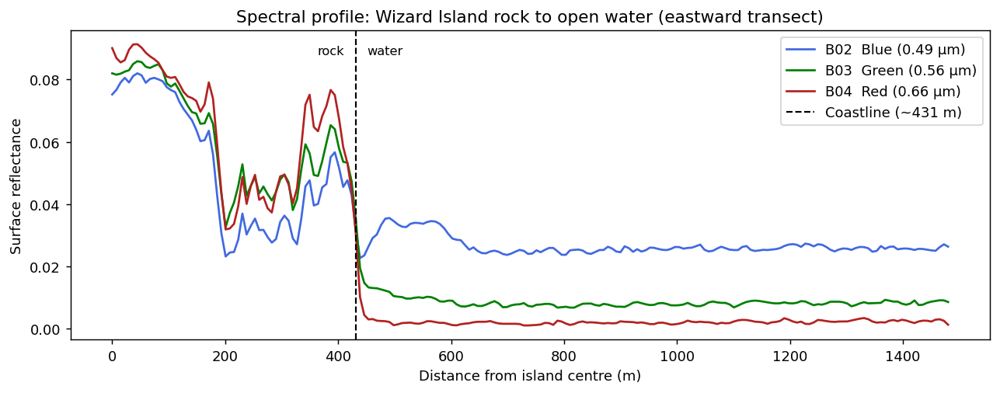

In [7]:
from scipy.ndimage import map_coordinates

rows_line = np.linspace(prof_r,  prof_r,  profile_len)
cols_line = np.linspace(prof_c0, prof_c1, profile_len)

# Convert DN to surface reflectance: Sentinel-2 baseline 4.0 stores values as
# reflectance * 10000 + 1000, so subtract 1000 and divide by 10000.
def to_refl(profile):
    return (profile - 1000) / 10000

b02_profile = to_refl(map_coordinates(b02[rs, cs], [rows_line, cols_line], order=1))
b03_profile = to_refl(map_coordinates(b03[rs, cs], [rows_line, cols_line], order=1))
b04_profile = to_refl(map_coordinates(b04[rs, cs], [rows_line, cols_line], order=1))
b08_profile = to_refl(map_coordinates(b08[rs, cs], [rows_line, cols_line], order=1))

distance_m = np.linspace(0, (prof_c1 - prof_c0) * 10, profile_len)

# Detect coastline as the steepest drop in NIR (water absorbs NIR almost completely)
nir_gradient  = np.gradient(b08_profile)
coastline_idx = np.argmin(nir_gradient)
coastline_m   = distance_m[coastline_idx]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(distance_m, b02_profile, color="royalblue", label="B02  Blue (0.49 µm)")
ax.plot(distance_m, b03_profile, color="green",     label="B03  Green (0.56 µm)")
ax.plot(distance_m, b04_profile, color="firebrick", label="B04  Red (0.66 µm)")
ax.axvline(coastline_m, color="k", lw=1.2, ls="--",
           label=f"Coastline (~{coastline_m:.0f} m)")
ymax = ax.get_ylim()[1]
ax.text(coastline_m - 20, ymax * 0.95, "rock",  fontsize=9, ha="right", va="top")
ax.text(coastline_m + 20, ymax * 0.95, "water", fontsize=9, ha="left",  va="top")
ax.set_xlabel("Distance from island centre (m)")
ax.set_ylabel("Surface reflectance")
ax.set_title("Spectral profile: Wizard Island rock to open water (eastward transect)")
ax.legend()
plt.tight_layout()
plt.show()


> Over deep water, each band settles to a stable plateau. These plateaus have nothing to do with the lake bottom — the water is far too deep for any light to reach it and return. Instead they reflect a simple physical process: when light enters the water, photons are either absorbed by water molecules (converted to heat, gone forever) or scattered in a random direction. Some scattered photons end up heading back upward toward the sensor. The further a photon travels before being absorbed, the more chances it has to scatter back up. Red photons are absorbed within a few metres — they barely get a chance. Blue photons travel tens of metres before being absorbed, accumulating many more opportunities to scatter back toward the sensor. That is why blue has the highest plateau value and red the lowest.

> 3. Look at the profile on the rock side of the coastline (left of the dashed line). The three bands track close together. What does this tell you about how volcanic rock reflects different wavelengths of visible light? Now look at what happens at the coastline — describe how each band responds as the surface transitions from rock to water.

> 4. Over deep water (far right of the profile), each band settles to a stable plateau.
>    - Which band has the highest plateau value? Which has the lowest? Is this ordering consistent with the explanation above?
>    - The blue band shows a small bump just after the coastline before settling to its plateau. What causes this bump? Why don't red and green show the same feature?
>    - If you were designing a sensor to estimate water depth in a clear lake, would you choose a wavelength that is absorbed quickly or slowly by water? Why?
>    - All optical methods have a fundamental depth limit regardless of wavelength. What causes it?

Answers:
3. The highest amplitude of reflectance comes from the red photons, while the lowest is blue. So the rock tends to absorb more blue than red. Then this changes when we get to the water, as the blue is now the highest amplitude for reflectance. So red is absorbed much faster than blue is, allowing the blue more chance to scatter back to the sensor for detection.

4. Blue has the highest plateau value and red has the lowest. This is consistent with the explanation above. Blue has this peak likely becuase right off the coast, there is a gradual change in the depth of the water, so this reflectance is high since the photons have less distance to travel before it hits the rock underneath, so it is likely not getting absorbed and many photons are able to scatter back to the top. Red and green probably get absorbed faster. I would choose a wavelength that is not absorbed fast, but one that is slow so that the photon has time to travel as far as it can go. There is a fundamental depth limit for all methods because of resolution? It can be difficult to get past a certain depth before all the data is noisy. So differentiating what is data vs what is some type of back scatter can be difficult.



### Near-Infrared: the vegetation band (B08, 0.84 µm)

The NIR band lies just beyond what the human eye can see. Two physical properties make it distinctive:

1. **Vegetation:** The internal cell structure of leaves — the spongy mesophyll layer — scatters NIR strongly upward. Healthy plants reflect ~40–50% of incident NIR, compared to ~5% of incident red.
2. **Water:** Liquid water absorbs NIR almost completely, for the same reason red and green are absorbed in the visible — the O-H bond's vibrational frequencies extend into NIR even more strongly. The lake appears nearly black regardless of depth.

Because both forest and rock reflect NIR strongly, the contrast between them is lower than in the red band. But the contrast between water and everything else is dramatic — NIR draws a sharp boundary around the lake that is much cleaner than any visible band.


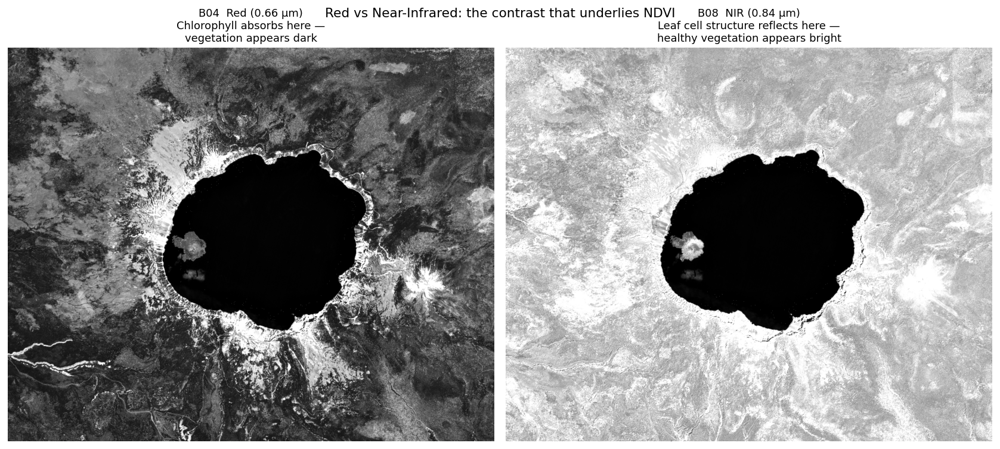

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)

bands_info = [
    (b04, "B04  Red (0.66 µm)",
     "Chlorophyll absorbs here —\nvegetation appears dark",
     2, 98),
    (b08, "B08  NIR (0.84 µm)",
     "Leaf cell structure reflects here —\nhealthy vegetation appears bright",
     2, 88),   # clip at 88th pct: prevents bright snow from compressing forest contrast
]

for ax, (band, title, subtitle, lo, hi) in zip(axes, bands_info):
    ax.imshow(pct(band, lo=lo, hi=hi), cmap="gray")
    ax.set_title(f"{title}\n{subtitle}", fontsize=10)
    ax.axis("off")

plt.suptitle("Red vs Near-Infrared: the contrast that underlies NDVI", fontsize=12)
plt.tight_layout()
plt.show()


> **Questions — NIR:**
> 1. Compare the boundary between the lake and the surrounding land in the red and NIR images. In which image is the boundary sharper and more distinct? What does this tell you about using NIR to map water bodies and shorelines?
> 2. Look at the forested slopes in both images. Forest appears dark in red and bright in NIR. What physical property of leaves explains the dramatic increase in reflectance between the two bands?
> 3. Now compare forest and bare rock in the NIR image. They appear similarly bright, with less contrast between them than in the red image. Why does rock reflect NIR strongly even though it has no leaf cell structure?

Answer:
1. The boundary is sharper in the NIR image because the lake is very dark while everything is much lighter around it, making the lake really pop out. This band of NIR is great for mapping water bodies and shorelines.
2. Leaves absorb red light so its easier to see in the red.
3. Likely rock does not absorb much of the light, so much of it gets reflected.  


### Shortwave-Infrared: mineralogy and moisture (B11, B12)

The SWIR bands (B11 at 1.61 µm and B12 at 2.19 µm) carry information invisible to the human eye but physically distinctive:

- **Ice and snow:** Water molecules in ice crystals absorb SWIR strongly. Snow that appears bright white in visible looks dark in SWIR — a key way to distinguish fresh snow from bright rock or sand.
- **Leaf water content:** Liquid water in plant leaves absorbs SWIR. Drier or stressed vegetation appears brighter in SWIR than well-watered vegetation.
- **Rock mineralogy:** Clay minerals and hydrothermal alteration products have diagnostic absorption features in the SWIR. The volcanic walls of the caldera may show subtle variation reflecting different rock types or weathering stages.

*Note: B11 and B12 are native 20 m resolution — resampled here to match the 10 m visible/NIR grid.*

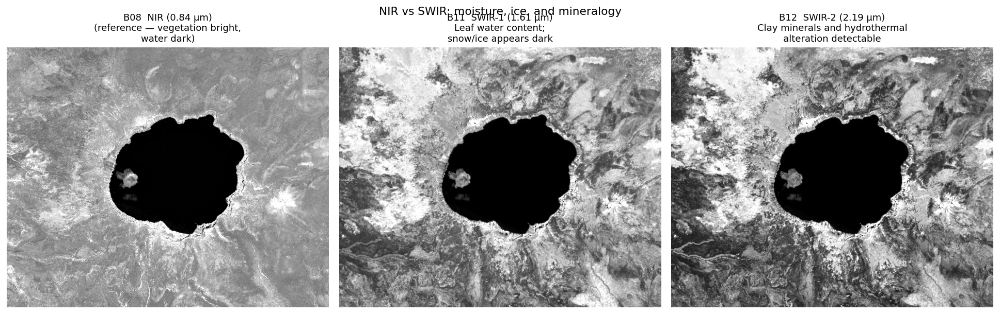

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

swir_bands = [
    (b08, "B08  NIR (0.84 µm)", "(reference — vegetation bright,\nwater dark)"),
    (b11, "B11  SWIR-1 (1.61 µm)", "Leaf water content;\nsnow/ice appears dark"),
    (b12, "B12  SWIR-2 (2.19 µm)", "Clay minerals and hydrothermal\nalteration detectable"),
]
for ax, (band, title, subtitle) in zip(axes, swir_bands):
    ax.imshow(pct(band), cmap="gray")
    ax.set_title(f"{title}\n{subtitle}", fontsize=10)
    ax.axis("off")

plt.suptitle("NIR vs SWIR: moisture, ice, and mineralogy", fontsize=12)
plt.tight_layout()
plt.show()

> **Questions — SWIR:**
> 1. The most striking difference in B11 and B12 compared to NIR is how snow and ice appear. Describe what you observe and explain why ice absorbs SWIR so strongly.
> 2. Compare the forest brightness in B08 (NIR) vs B11 (SWIR-1). Does the forest appear brighter or darker in SWIR? What does this tell you about the water content of the trees?
> 3. Look carefully at the caldera walls in B12. Can you see color or brightness variation that is not obvious in the visible bands? What geological process might produce that variation?

Answer:
1. NIR covers much of vegetation, where anywhere with lots of vegetation appears light. However water absorbs SWIR very strongly, so the snow and ice appears very visible. Plants also have water, but snow and ice are pure water, and reflect mcuh stronger than vegetation. There are more detailed darker spots in the B11 and B12 images.
2. They appear darker in SWIR, so they do have a good amount of water content.
3. You can see texture variations in the caldera walls, erosion or weathering effects can cause different minerals to appear.

### False-color composites

You have now seen how each wavelength region responds to the scene. We build two more composites that assign non-visible bands to display channels, revealing features that are invisible in the true-color image you examined at the start.

| Composite | Band → Red | Band → Green | Band → Blue | Key use |
|---|---|---|---|---|
| **Color Infrared (CIR)** | B08 NIR | B04 Red | B03 Green | Vegetation health, water depth |
| **Geology** | B12 SWIR-2 | B11 SWIR-1 | B04 Red | Mineralogy, discriminates snow from rock |

#### Color Infrared / CIR (B08→R, B04→G, B03→B)

Replaces the blue display channel with red, green with red, and red with NIR. This "shifts" the display one channel toward longer wavelengths, making NIR information appear as red. Widely used in ecology and agriculture; originally designed to mimic wartime color-infrared aerial film.

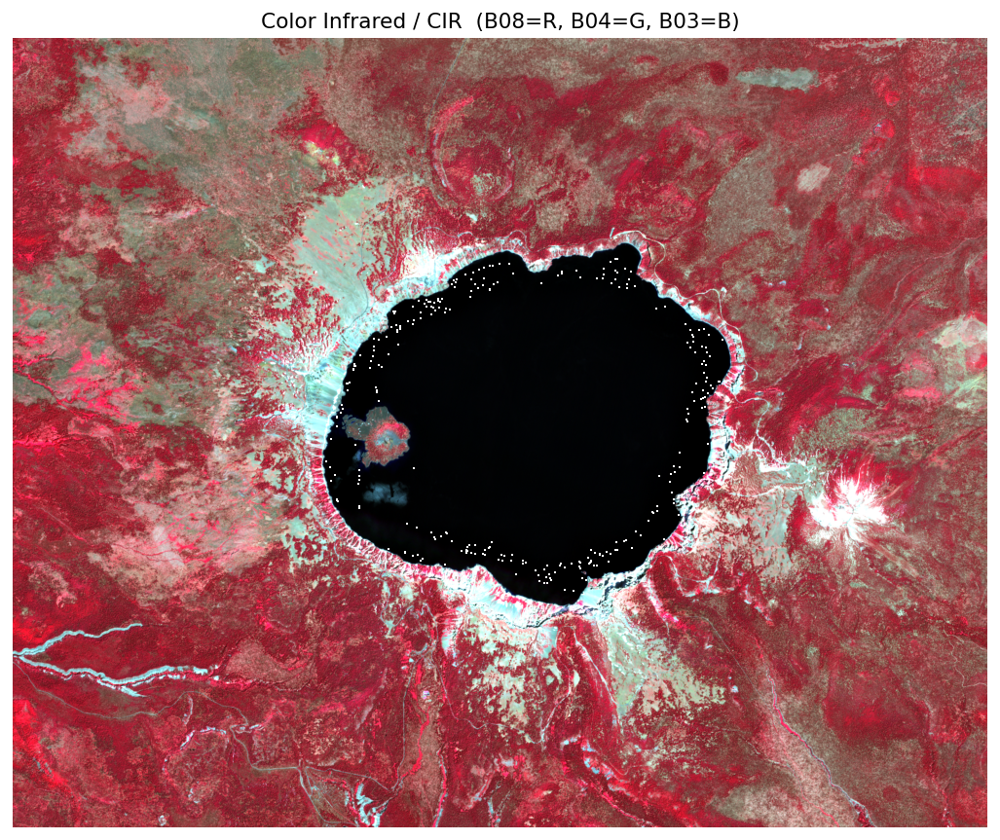

In [10]:
cir = make_composite(b08, b04, b03)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(cir)
ax.set_title("Color Infrared / CIR  (B08=R, B04=G, B03=B)", fontsize=12)
ax.axis("off")
plt.tight_layout()
plt.show()

> **Questions — CIR:**
> 1. What color is the dense conifer forest in CIR? Explain this in terms of which bands are assigned to which display channels and what you observed about forest reflectance in the individual band exploration.
> 2. How does the lake appear in CIR? Is there any color variation between the shallow water near the shore and the deep open water?
> 3. How does Wizard Island appear relative to the surrounding forest? What does this tell you about its surface cover?
> 4. Look at the snow patches on the caldera rim. How easy is it to distinguish snow from bare rock in CIR? Keep this in mind when you look at the geology composite.

Answer:
1. The colors of the forest is red. Band 08 (NIR) became red, so BO4 red became green, and BO3 green became blue.
2. The color of the lake appears black, but near the shallow water it does appear a bit green or blue.
3. There is a lot of red on the Wizard Island in some spots, but it is a bit lighter in red. So maybe this surface cover is less healthy than the surrounding forest.
4. While a little similar, the ice of the caldera rim is very white compared to the gray of the bare rock, so it is pretty easy to see the difference.


#### Geology composite (B12→R, B11→G, B04→B)

Replaces the visible display channels with SWIR bands sensitive to mineralogy. Because ice absorbs SWIR strongly, snow that appears white in true color appears dark here — making it easy to separate snow from bright rock. Clay minerals and hydrothermal alteration zones appear in distinct colors.

In [ ]:
geology = make_composite(b12, b11, b04)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(geology)
ax.set_title("Geology  (B12=R, B11=G, B04=B)", fontsize=12)
ax.axis("off")
plt.tight_layout()
plt.show()

> **Questions — geology:**
> 1. Look at the caldera rim — the ring of bare rock immediately surrounding the lake. What color does it appear in the geology composite? B12 is assigned to red, B11 to green, and B04 to blue. Which channels must be low and which high to produce this color?
> 2. Look at the yellow-orange patches to the northwest of the lake. This area borders the Pumice Desert — a broad flat plain of pyroclastic deposits from the Mount Mazama eruption that are too thick and nutrient-poor to support forest growth. Pyroclastic deposits are silica-rich and dry, with little vegetation or moisture to absorb SWIR. Which channels would you expect to be high there, and is that consistent with the yellow-orange color you see? How does this surface look different from the forested areas surrounding it?
> 3. Compare how snow appears in the geology composite versus CIR. Is it easier or harder to distinguish snow from bare rock in the geology composite? Explain why in terms of what B11 and B12 measure for snow.
> 4. How does the forest appear in the geology composite compared to CIR? Explain the change in terms of what B11 and B12 measure for vegetation.


### NDVI

Instead of combining bands for display, we can compute a mathematical index that directly exploits the contrast we saw between B04 and B08. NDVI encodes, in a single number, how much more strongly a surface reflects NIR than red — the signature of healthy vegetation.

$$\text{NDVI} = \frac{\rho_{\text{NIR}} - \rho_{\text{red}}}{\rho_{\text{NIR}} + \rho_{\text{red}}}$$

In [ ]:
with np.errstate(divide="ignore", invalid="ignore"):
    ndvi = (b08 - b04) / (b08 + b04)
ndvi = np.where(np.isfinite(ndvi), ndvi, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(true_color)
axes[0].set_title("True color", fontsize=11)
axes[0].axis("off")

im = axes[1].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.8)
axes[1].set_title("NDVI", fontsize=11)
axes[1].axis("off")
plt.colorbar(im, ax=axes[1], shrink=0.7, label="NDVI")

plt.suptitle("Crater Lake — true color vs NDVI", fontsize=12)
plt.tight_layout()
plt.show()

print(f"NDVI range: {np.nanmin(ndvi):.2f} to {np.nanmax(ndvi):.2f}")
print(f"Mean NDVI over forested area: ~{np.nanmean(ndvi[ndvi > 0.3]):.2f}")


> **Questions — NDVI:**
> 1. What NDVI value does the lake surface have, and why? What physical interpretation does a negative NDVI carry?
> 2. The caldera rim is bare volcanic rock with very little vegetation. Where do you expect it to fall on the NDVI scale, and does the map confirm this?
> 3. Is there any spatial variation in NDVI within the forested area? What might cause patches of lower NDVI within an otherwise dense forest?
> 4. Wizard Island erupted *inside* the caldera after the Mount Mazama collapse (~7,700 years ago), making it significantly younger than the caldera walls. Compare the NDVI of Wizard Island to the surrounding caldera rim. Do they differ? If so, explain the difference in terms of surface age, soil development, and vegetation establishment on volcanic terrain.

---
## Part II (Optional): Download your own Sentinel-2 scene

Microsoft Planetary Computer hosts the full Sentinel-2 archive and provides free access with no account or credentials required. In this section you will search for a scene of your own choosing, download the relevant bands, and apply the same composites and indices from Part I to a new location.

### Choosing a location

Think about a location where the spectral contrasts from Part I would be interesting:
- A volcanic landscape with bare rock, lava flows, and potential pyroclastic deposits
- A river delta or wetland where vegetation, water, and sediment interact
- An agricultural region where NDVI would reveal crop health or irrigation patterns
- A glaciated mountain range where SWIR separates snow from rock

You will need a rough bounding box for your area (min/max longitude and latitude). A quick way to get coordinates is to right-click any location in Google Maps and copy the latitude/longitude.


### Search for scenes

Edit the bounding box and date range below. The search returns Sentinel-2 L2A scenes (atmospherically corrected surface reflectance — the same product used in Part I) sorted by cloud cover so the clearest scene comes first.


In [ ]:
import pystac_client
import planetary_computer

# ── Define your area of interest and date range ───────────────────────────────
# Bounding box: [min_lon, min_lat, max_lon, max_lat]
BBOX       = [-122.5, 42.7, -121.8, 43.2]   # example: Crater Lake region — change this!
DATE_START = "2024-07-01"
DATE_END   = "2024-08-31"

# ── Search the Planetary Computer STAC catalogue ──────────────────────────────
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=BBOX,
    datetime=f"{DATE_START}/{DATE_END}",
    query={"eo:cloud_cover": {"lt": 20}},
    sortby="+properties.eo:cloud_cover",   # least cloudy first
    max_items=5,
)

items = list(search.items())
print(f"Found {len(items)} scene(s):")
for item in items:
    print(f"  {item.datetime.date()}  "
          f"cloud cover: {item.properties['eo:cloud_cover']:.1f}%  "
          f"id: {item.id}")


### Download bands

The cell below downloads the six bands used in Part I (B02, B03, B04, B08, B11, B12) from the least cloudy scene. B11 and B12 are at 20 m resolution and are resampled to 10 m to match the visible and NIR bands.

Depending on your area and scene size this may take a few minutes.


In [ ]:
import io, requests

# Use the first (least cloudy) result
item = items[0]
print(f"Downloading scene: {item.id}")
print(f"Date: {item.datetime.date()}  "
      f"Cloud cover: {item.properties['eo:cloud_cover']:.1f}%")

BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]
band_arrays = {}
target_shape = None

for band in BANDS:
    href = item.assets[band].href
    print(f"  {band} ...", end=" ", flush=True)
    r = requests.get(href)
    r.raise_for_status()
    with rasterio.open(io.BytesIO(r.content)) as src:
        if target_shape is None:                   # set target from first 10 m band
            target_shape    = (src.height, src.width)
            scene_crs       = src.crs
            scene_transform = src.transform
        if (src.height, src.width) != target_shape:  # resample 20 m → 10 m
            arr = src.read(1, out_shape=target_shape,
                           resampling=rasterio.enums.Resampling.bilinear).astype(np.float32)
        else:
            arr = src.read(1).astype(np.float32)
    band_arrays[band] = arr
    print("done")

my_b02, my_b03, my_b04 = band_arrays["B02"], band_arrays["B03"], band_arrays["B04"]
my_b08 = band_arrays["B08"]
my_b11, my_b12 = band_arrays["B11"], band_arrays["B12"]
print("\nAll bands loaded.")


### Explore your scene

The cells below apply the same composites and NDVI from Part I to your scene.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

composites = [
    (make_composite(my_b04, my_b03, my_b02), "True color (B04/B03/B02)"),
    (make_composite(my_b08, my_b04, my_b03), "Color Infrared (B08/B04/B03)"),
    (make_composite(my_b12, my_b11, my_b04), "Geology (B12/B11/B04)"),
]
for ax, (img, title) in zip(axes, composites):
    ax.imshow(img)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

plt.suptitle(f"Scene: {item.id[:60]}", fontsize=10)
plt.tight_layout()
plt.show()


In [ ]:
with np.errstate(divide="ignore", invalid="ignore"):
    my_ndvi = (my_b08 - my_b04) / (my_b08 + my_b04)

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(my_ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.8)
plt.colorbar(im, ax=ax, label="NDVI", shrink=0.7)
ax.set_title("NDVI — your scene", fontsize=12)
ax.axis("off")
plt.tight_layout()
plt.show()


> **Questions — your scene:**
> 1. Where did you choose and why? What surface types did you expect to find there?
> 2. Compare the true color, CIR, and geology composites. Which reveals the most information about your scene? What features are visible in one composite but not the others?
> 3. Look at the NDVI map. Identify one area of high NDVI and one of low NDVI and explain what surface type each corresponds to.
> 4. If you were a geologist or ecologist studying this region, which band or composite would you find most useful and why?


---
## Summary

- Individual spectral bands (Blue, Green, Red, NIR, SWIR) each highlight different physical properties of the surface.
- False-color composites reveal features invisible to the human eye: CIR shows vegetation health; the geology composite separates snow from bright rock and highlights mineralogy.
- NDVI quantifies photosynthetic activity from the NIR/Red contrast and can be mapped spatially across an entire scene.
- The same principles apply to any Sentinel-2 scene — including the one you downloaded and explored in Part II.
